# 2. Atmosphere scenarios

Every showcase target ships five precomputed scenarios. Four are physical
atmospheres from POSEIDON; the fifth, `flat`, is a featureless baseline used
as the null reference.

| Scenario | Cloud model | Metallicity | What it represents |
|---|---|---|---|
| `clear` | cloud-free | solar (`log_Met = 0`) | The optimistic case — full-amplitude molecular features |
| `cloudy` | `MacMad17` deck at 10<sup>-3</sup> bar | solar | An opaque grey deck truncating the features from below |
| `hazy` | `MacMad17` `deck_haze` | solar | A scattering haze steepening the blue continuum |
| `high_metallicity` | cloud-free | 100× solar (`log_Met = 2`) | Higher mean molecular weight → smaller scale height |
| `flat` | — | — | Analytic featureless (R<sub>p</sub>/R<sub>s</sub>)² line |

All four physical scenarios use C/O = 0.55 and a single isothermal T = T<sub>eq</sub>
layer, not a real P–T profile.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("terminator", lazuli_exo.__file__)

terminator /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/terminator/src/lazuli_exo/__init__.py


## The recorded settings

The scenario definitions are frozen into each table's `meta`, so you can read
back exactly what was run rather than trusting the table above.

In [2]:
PLANET = "WASP-39 b"
scenarios = lazuli_exo.list_scenarios(PLANET)

rows = []
for s in scenarios:
    m = lazuli_exo.observe(PLANET, scenario=s, n_transits=1).meta["model"]
    rows.append((s, m.get("cloud_model"), m.get("cloud_type"),
                 m.get("cloud_params"), m.get("C_to_O"), m.get("log_Met")))

hdr = ("scenario", "cloud_model", "cloud_type", "cloud_params",
       "C/O", "log_Met")
print(f"{hdr[0]:18s}{hdr[1]:12s}{hdr[2]:12s}{hdr[3]:22s}"
      f"{hdr[4]:6s}{hdr[5]}")
for r in rows:
    print(f"{str(r[0]):18s}{str(r[1]):12s}{str(r[2]):12s}"
          f"{str(r[3]):22s}{str(r[4]):6s}{r[5]}")

scenario          cloud_model cloud_type  cloud_params          C/O   log_Met
clear             cloud-free  None        []                    0.55  0.0
cloudy            MacMad17    deck        [-3.0]                0.55  0.0
flat              None        None        None                  None  None
hazy              MacMad17    deck_haze   [2.0, -6.0, 2.0]      0.55  0.0
high_metallicity  cloud-free  None        []                    0.55  2.0


## The four physical scenarios side by side

Native-resolution models, no instrument noise. `clear` has the deepest
molecular bands; the cloud deck in `cloudy` clips them from below; `hazy`
adds a rising blue slope; `high_metallicity` compresses everything because
the mean molecular weight — and so the scale height — has changed.

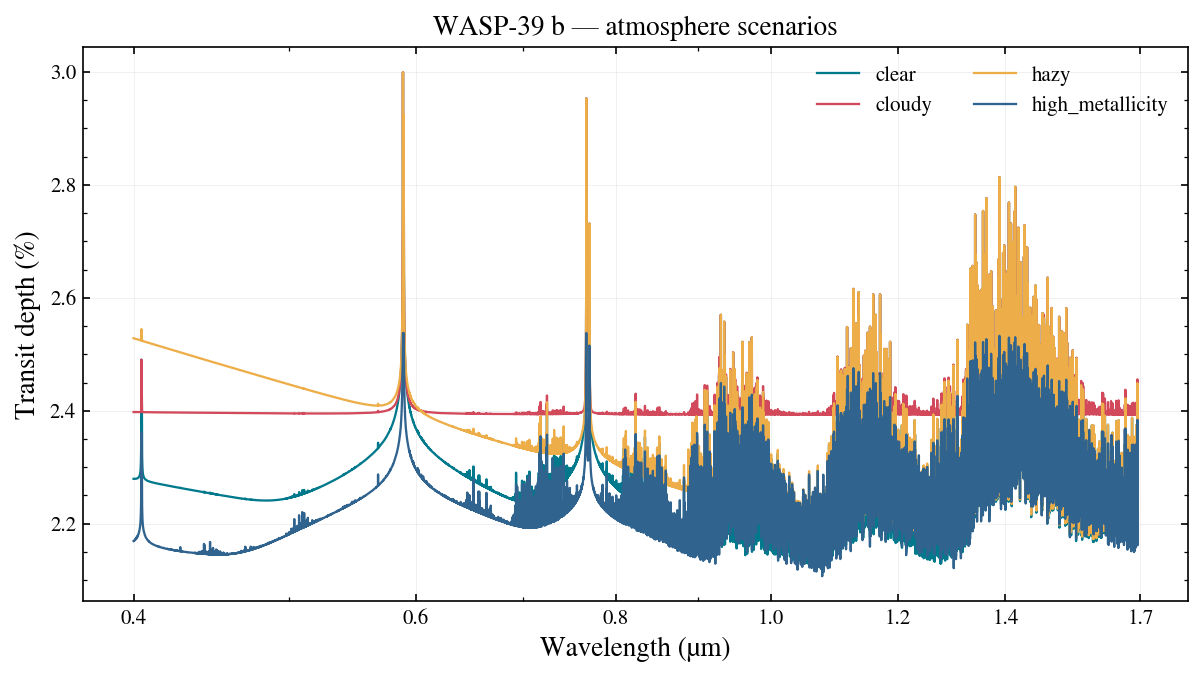

In [3]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))

for s in ["clear", "cloudy", "hazy", "high_metallicity"]:
    obs = lazuli_exo.observe(PLANET, scenario=s, n_transits=1, R=100)
    ax.plot(obs.model_wavelength, obs.model_depth * 100.0, lw=1.1, label=s)

ax.set_xscale("log")
ax.set_xticks([0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.7])
ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax.set_xlabel("Wavelength (µm)")
ax.set_ylabel("Transit depth (%)")
ax.set_title(f"{PLANET} — atmosphere scenarios")
ax.legend(frameon=False, ncol=2)
plt.show()

## The `flat` baseline

`flat` is the featureless reference: a constant (R<sub>p</sub>/R<sub>s</sub>)²
line. It is what the template S/N is measured *against*, so running `detect()`
on it should return essentially zero.

In [4]:
obs_clear = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1)
obs_flat = lazuli_exo.observe(PLANET, scenario="flat", n_transits=1)

snr_clear = obs_clear.detect()["template_snr_diagonal"]
snr_flat = obs_flat.detect()["template_snr_diagonal"]

print(f"flat_depth (from the flat table): {obs_flat.flat_depth * 100:.4f} %")
print(f"flat model spread:                "
      f"{np.ptp(obs_flat.depth) * 1e6:.3g} ppm")
print()
print(f"template S/N, clear: {snr_clear:8.2f}")
print(f"template S/N, flat:  {snr_flat:8.2f}")

assert snr_flat < 1.0, "the flat baseline must carry no template signal"
assert snr_clear > 50 * max(snr_flat, 1e-6)
print("\nOK — flat is featureless, clear is not.")

flat_depth (from the flat table): 2.1228 %
flat model spread:                0 ppm

template S/N, clear:    85.17
template S/N, flat:      0.00

OK — flat is featureless, clear is not.


## Feature amplitude across scenarios and targets

The same comparison for a handful of targets spanning the sample: a hot
Saturn, a warm Neptune, a sub-Neptune, and a temperate terrestrial. Note the
vertical scale — this is one transit each, so the absolute values are driven
as much by host brightness as by atmosphere.

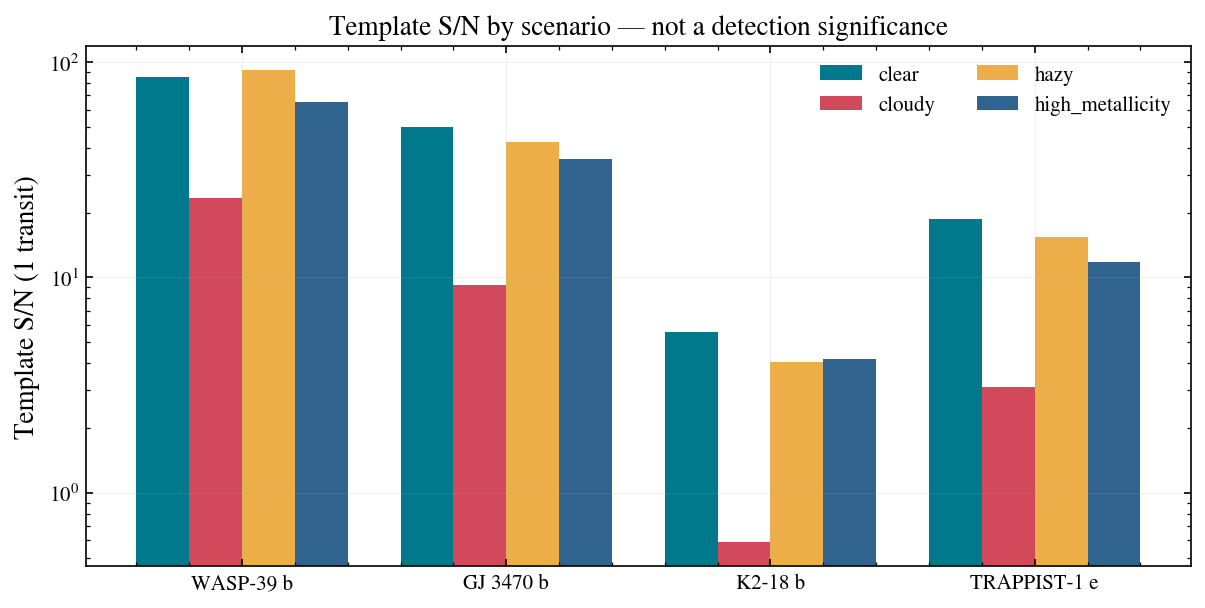

WASP-39 b      clear=   85.17  cloudy=   23.42  hazy=   92.01  high_metallicity=   65.28
GJ 3470 b      clear=   49.98  cloudy=    9.24  hazy=   42.34  high_metallicity=   35.46
K2-18 b        clear=    5.59  cloudy=    0.59  hazy=    4.05  high_metallicity=    4.18
TRAPPIST-1 e   clear=   18.72  cloudy=    3.11  hazy=   15.45  high_metallicity=   11.77


In [5]:
TARGETS = ["WASP-39 b", "GJ 3470 b", "K2-18 b", "TRAPPIST-1 e"]
PHYSICAL = ["clear", "cloudy", "hazy", "high_metallicity"]

snr = {t: [lazuli_exo.observe(t, scenario=s, n_transits=1)
           .detect()["template_snr_diagonal"] for s in PHYSICAL]
       for t in TARGETS}

fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(TARGETS))
width = 0.2
for i, s in enumerate(PHYSICAL):
    ax.bar(x + (i - 1.5) * width, [snr[t][i] for t in TARGETS],
           width, label=s)

ax.set_xticks(x)
ax.set_xticklabels(TARGETS)
ax.set_yscale("log")
ax.set_ylabel("Template S/N (1 transit)")
ax.set_title("Template S/N by scenario — not a detection significance")
ax.legend(frameon=False, ncol=2)
plt.show()

for t in TARGETS:
    print(f"{t:14s} " + "  ".join(f"{s}={v:8.2f}"
                                  for s, v in zip(PHYSICAL, snr[t])))

Two orderings hold for every target: the cloud deck mutes the features, and
higher metallicity shrinks the scale height, so both score below `clear`.

`hazy` is the interesting one — it can score *above* `clear`. That is not a
bug, and it is a good illustration of what the statistic actually measures.
The template norm rewards **any** deviation from a flat line, and the haze
contributes a steep Rayleigh-like slope across the blue half of the band. A
smooth continuum slope is a large departure from flat even though it carries
no molecular information at all. Read `template_snr_diagonal` as "how much
structure is there", never as "how much atmosphere is detectable".

In [6]:
for t in TARGETS:
    v = dict(zip(PHYSICAL, snr[t]))
    assert v["clear"] > v["cloudy"], t
    assert v["clear"] > v["high_metallicity"], t
print("OK — clear > cloudy and clear > high_metallicity for every target.\n")

print(f"{'planet':14s}{'clear':>10s}{'hazy':>10s}{'hazy/clear':>13s}")
for t in TARGETS:
    v = dict(zip(PHYSICAL, snr[t]))
    print(f"{t:14s}{v['clear']:10.2f}{v['hazy']:10.2f}"
          f"{v['hazy'] / v['clear']:13.2f}")

OK — clear > cloudy and clear > high_metallicity for every target.

planet             clear      hazy   hazy/clear
WASP-39 b          85.17     92.01         1.08
GJ 3470 b          49.98     42.34         0.85
K2-18 b             5.59      4.05         0.72
TRAPPIST-1 e       18.72     15.45         0.83


## Which bands carry the signal

Splitting the same statistic by the fixed wavelength masks shows *where* in
the band the scenarios differ. Again: overlapping masks, all species mixed
together — read these as "where the spectrum has structure", not as molecule
detections.

In [7]:
from lazuli_exo.detect import BAND_MASKS

mols = sorted(BAND_MASKS)

print(f"{PLANET}, 1 transit, band-restricted template norms\n")
print(f"{'scenario':18s}" + "".join(f"{m:>10s}" for m in mols))
for s in PHYSICAL + ["flat"]:
    bands = lazuli_exo.observe(PLANET, scenario=s,
                               n_transits=1).detect()["band_snr"]
    print(f"{s:18s}" + "".join(f"{bands[m]:10.2f}" for m in mols))

WASP-39 b, 1 transit, band-restricted template norms

scenario                 CH4       CO2       H2O         K        Na
clear                  24.75     32.83     57.35     21.03     28.91
cloudy                  4.24     11.95     18.54      5.90      9.20
hazy                   28.57     27.98     40.51     15.79     26.28
high_metallicity       20.83     24.76     46.39     10.52     16.54
flat                    0.00      0.00      0.00      0.00      0.00


Notice that going `clear` → `hazy`, *every* band norm drops — H2O most of all,
as the molecular bands get partly veiled — and yet the total went **up**. The
extra structure is living outside every mask, in the blue continuum below
0.575 µm where the haze slope is steepest and no band mask reaches.

This is the clearest possible warning about the statistic: the total is
dominated by a smooth continuum slope carrying no molecular information.

In [8]:
def chi2_split(obs):
    """Template chi2 inside any band mask vs. outside all of them."""
    w = 1.0 / obs.depth_err ** 2
    dbar = np.sum(w * obs.depth) / np.sum(w)
    chi2 = w * (obs.depth - dbar) ** 2

    in_mask = np.zeros(obs.wavelength.shape, dtype=bool)
    for spans in BAND_MASKS.values():
        for lo, hi in spans:
            in_mask |= (obs.wavelength >= lo) & (obs.wavelength <= hi)
    return np.sqrt(chi2[in_mask].sum()), np.sqrt(chi2[~in_mask].sum())


print(f"{'scenario':18s}{'total S/N':>11s}{'in-mask':>10s}"
      f"{'out-of-mask':>14s}{'out fraction':>14s}")
for s in ["clear", "hazy"]:
    o = lazuli_exo.observe(PLANET, scenario=s, n_transits=1)
    inside, outside = chi2_split(o)
    total = o.detect()["template_snr_diagonal"]
    print(f"{s:18s}{total:11.2f}{inside:10.2f}{outside:14.2f}"
          f"{(outside / total) ** 2:14.2f}")

scenario            total S/N   in-mask   out-of-mask  out fraction
clear                   85.17     70.76         47.41          0.31
hazy                    92.01     58.13         71.32          0.60


## The cold-planet temperature floor

The fastchem equilibrium-chemistry grid used to build the model tables has a
hard floor at 300 K. Three targets sit below it and were clamped for both the
isotherm and the chemistry lookup. That is recorded per table as
`T_clamped`, so you never have to guess.

In [9]:
import warnings

print(f"{'planet':14s}{'T_eq (K)':>10s}{'T_iso (K)':>11s}  clamped")
with warnings.catch_warnings():
    # three bright hosts warn about residual detector saturation;
    # notebook 05 covers what that means
    warnings.simplefilter("ignore", UserWarning)
    for p in lazuli_exo.list_planets():
        m = lazuli_exo.observe(p, scenario="clear",
                               n_transits=1).meta["model"]
        flag = "  <-- clamped" if m.get("T_clamped") else ""
        print(f"{p:14s}{m['T_eq_K']:10.0f}{m['T_iso_K']:11.0f}{flag}")

planet          T_eq (K)  T_iso (K)  clamped
GJ 1214 b            567        567
GJ 3470 b            594        594
HAT-P-11 b           838        838
HD 189733 b         1209       1209
HD 209458 b         1459       1459
K2-18 b              284        300  <-- clamped
LHS 1140 b           226        300  <-- clamped
TOI-270 d            383        383
TRAPPIST-1 e         250        300  <-- clamped
WASP-107 b           736        736
WASP-12 b           2601       2601
WASP-121 b          2409       2409


WASP-39 b           1166       1166


WASP-96 b           1285       1285


## Summary

- Four physical scenarios (`clear`, `cloudy`, `hazy`, `high_metallicity`)
  plus a featureless `flat` baseline, all frozen into the tables with their
  settings in `meta["model"]`.
- `clear` maximizes feature amplitude; clouds truncate it, high metallicity
  compresses it.
- `flat` carries no template signal by construction — it is the reference the
  statistic is measured against.
- Sub-300 K targets are clamped to the chemistry grid floor and flagged with
  `T_clamped`.

Next: [transits and binning](03_transits_and_binning.ipynb) — how `n_transits`
and `R` trade against each other.